# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [19]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [20]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [21]:

DATA_PATH = RAW_DATA_DIR / "wine.csv"

# carga el archivo en un DataFrame llamado df
df = pd.read_csv(DATA_PATH)

In [22]:
# reporta forma, tipos, nulos, duplicados y distribución de target
print("Forma:", df.shape)

print("\nTipos de datos:")
print(df.dtypes)

print("\nNulos por columna:")
print(df.isna().sum())

print("\nFilas duplicadas:", df.duplicated().sum())

print("\nDistribución de target:")
print(df["target"].value_counts().sort_index())
print(df["target"].value_counts(normalize=True).sort_index().round(3))

Forma: (178, 14)

Tipos de datos:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Nulos por columna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             

**Conclusión de calidad:**

>  El dataset tiene 178 vinos y 13 variables numéricas, sin nulos ni duplicados, así que no hubo que limpiar nada. Las clases estan desbalanceadas (59, 71 y 48 vinos). Por se hace un split estratificado que mantiene las proporciones de cada clase en train y test.

## 2. Split train/test

In [23]:
# crea train_df (80 %) y test_df (20 %)
# Requisitos: stratify=df["target"] y random_state=RANDOM_STATE
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["target"],
    random_state=RANDOM_STATE
)


In [24]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

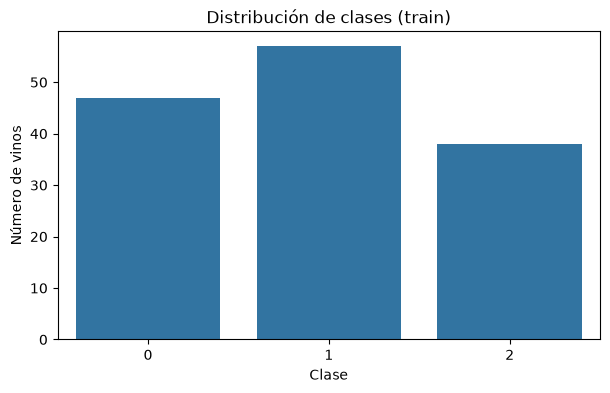

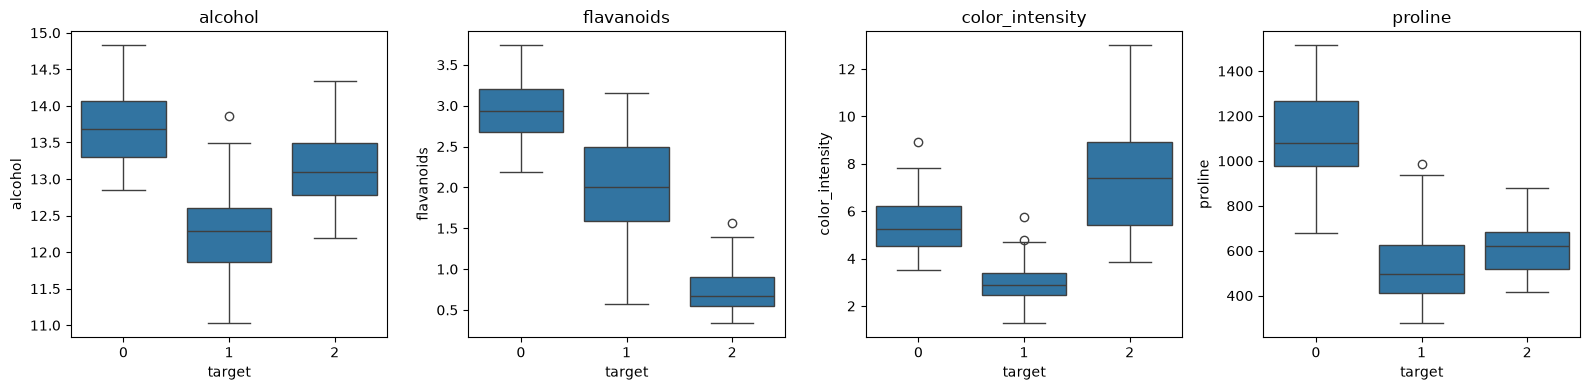

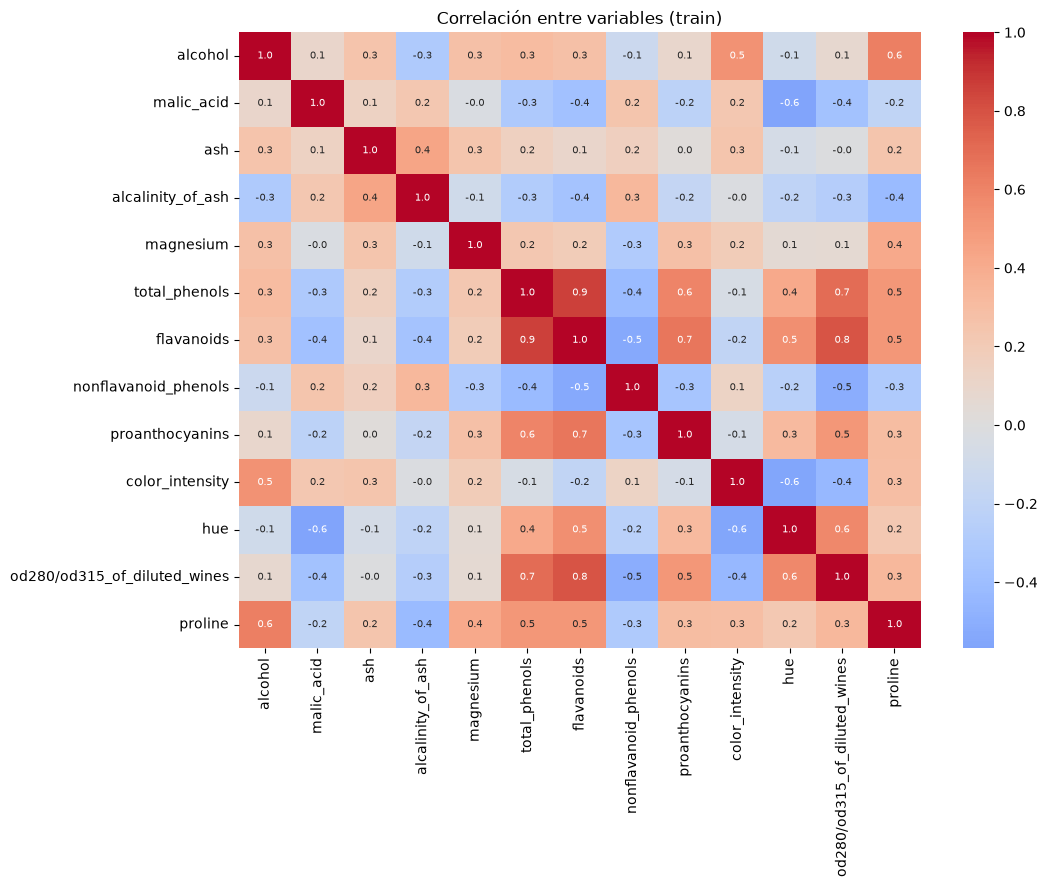

                                mean     std     min      max
alcohol                        12.97    0.80   11.03    14.83
malic_acid                      2.34    1.10    0.74     5.80
ash                             2.36    0.27    1.36     3.22
alcalinity_of_ash              19.63    3.38   10.60    30.00
magnesium                      99.63   14.94   70.00   162.00
total_phenols                   2.27    0.62    0.98     3.88
flavanoids                      1.99    0.95    0.34     3.74
nonflavanoid_phenols            0.36    0.12    0.13     0.63
proanthocyanins                 1.60    0.58    0.42     3.58
color_intensity                 4.99    2.33    1.28    13.00
hue                             0.95    0.23    0.48     1.71
od280/od315_of_diluted_wines    2.61    0.69    1.27     3.92
proline                       739.48  301.50  278.00  1515.00


In [25]:
# crea al menos tres visualizaciones usando solamente train_df
features = [c for c in train_df.columns if c != "target"]

# 1. distribución de clases
sns.countplot(data=train_df, x="target")
plt.title("Distribución de clases (train)")
plt.xlabel("Clase")
plt.ylabel("Número de vinos")
plt.show()

# 2. boxplots de variables relevantes por clase
key_features = ["alcohol", "flavanoids", "color_intensity", "proline"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key_features):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

# 3. correlaciones entre variables
plt.figure(figsize=(11, 8))
sns.heatmap(train_df[features].corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlación entre variables (train)")
plt.show()

# 4. escalas de las variables
print(train_df[features].describe().loc[["mean", "std", "min", "max"]].round(2).T)


**Hallazgos:**

1. Las escalas son muy distintas: `proline` ronda los 740, mientras que `hue` está cerca de 1. Hay que escalar las variables para la regresión logística y KNN.
   
2. Algunas variables separan bien las clases: `flavanoids` (promedio de 2.93, 2.01 y 0.78 por clase), `proline` (la clase 0 tiene unos 1092 contra 526 y 623) y `color_intensity` (la clase 2 es la más alta).

3. Hay variables muy correlacionadas entre sí: `flavanoids` con `total_phenols` (0.86) y con `od280/od315_of_diluted_wines` (0.79).

## 4. Persistencia de datos y contrato

In [26]:
# reinicia los índices y guarda train.csv y test.csv sin el índice
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

# crea data_contract.json con target, features, random_state y test_size
contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}

(ARTIFACTS_DIR / "data_contract.json").write_text(
    json.dumps(contract, indent=2),
    encoding="utf-8"
)


347

In [27]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ x] Cargué el CSV desde `data/raw`.
- [ x] Revisé calidad y distribución de la clase.
- [ x] Realicé un split estratificado.
- [ x] No exploré el conjunto de test.
- [ x] Guardé los tres artefactos requeridos.